# 289. The reverse direction: human BCL-2 family → *C. elegans* (Ced9), human CD47 → *B. burgdorferi* (P66)

**Question.** Notebook 241 searched Ced9 (*C. elegans* CED-9) and P66 (the Lyme bacterium's
outer-membrane protein) against the human proteome; neither partner, BCL2 or CD47, came near
the top. Here the human proteins are the queries and the other species' proteomes are the
database. Does kmerseek find Ced9 from the human BCL-2 family, and P66 from CD47? For the
BCL-2 family the calls of its nine members are also combined at each Ced9 residue, the
mirror of notebook 285 ([PR 128](https://github.com/seanome/2024-kmerseek-analysis/pull/128)).

**Decision this informs.** If either partner passes, kmerseek can be described as finding
it from the human side, and the paper can report the pair as found in one direction. If not,
both pairs stay out of reach in both directions at notebook 241's settings.

**Rule, committed before any search ran** (`289_reverse_search.py`,
[2f629f6](https://github.com/seanome/2024-kmerseek-analysis/commit/2f629f6)):

1. A call with an E-value gives its target protein $p = 1 - e^{-E \cdot L_t / L_{db}}$
   ($L_t$ the protein's length, $L_{db}$ the proteome's total length); no E-value fit, $p = 1$.
2. One query: a target's score is its lowest $p$ over all calls at all 152 settings.
3. The BCL-2 family together: at each residue of a target, each of the nine queries gives its
   lowest $p$ over calls covering that residue (1 without one); Fisher's method combines the
   nine (χ², 18 degrees of freedom); the target's score is its lowest combined $p$.
4. Null: the 20 dipeptide-shuffled copies of each query (same length, same count of every
   adjacent residue pair). For the family, pool $i$ is the $i$-th copy of each member.

**Pass**, for each case: the partner ranks in the **top 10** of its proteome AND scores better
than **at least 19 of the 20** shuffles. **Lower p is better.** The score ranks proteins; it is
not a calibrated p-value, because each protein's $p$ is its best over 152 settings and many
residues.

## Data

- **Queries**: GENCODE v49 canonical translations of BAK1, BAX, BCL2, BCL2A1, BCL2L1, BCL2L10,
  BCL2L2, BOK, MCL1 (BCL2's Ensembl 115 paralog group, notebook 285) and CD47, plus 20
  shuffles of each (`289_queries.fa`, 210 sequences).
- **Databases**: UniProt reference proteomes, release 2026_03, one protein per gene:
  *C. elegans* UP000001940 (19_792 proteins; Ced9 = P41958, the sequence notebook 241
  searched) and *B. burgdorferi* B31 UP000001807 (1_291 proteins; P66 = H7C7N8, 618 aa, of
  which notebook 241 searched residues 22-618).
- **Search**: kmerseek 982a055, notebook 241's 152 settings and driver, gapless (no chaining),
  every call kept. Sherlock job 48677815, 2026-10-20, 1 h 44 min.
- **Tables read here**: `289_summary/<species>/`, copied from
  `$SCRATCH/289-reverse-search/<species>/gapless/summary/`; UniProt motif and feature tables
  `289_summary/bh_motifs_uniprot.csv` (from notebook 285) and `cd47_p66_features_uniprot.csv`.

In [1]:
import gzip
import json
import math
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.stats import chi2

sys.path.insert(0, str(Path.cwd()))
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(70)
S = Path("289_summary")
FIG = Path("../figures/289")
C = pf.OKABE_ITO
FAMILY = ["BAK1", "BAX", "BCL2", "BCL2A1", "BCL2L1", "BCL2L10", "BCL2L2", "BOK", "MCL1"]
TOOL = ("kmerseek 982a055, notebook 241's 152 alphabet-ksize settings, gapless calls. "
        "Queries: human (GENCODE v49)")
single = {s: pl.read_csv(S / s / "289_single_query_partner.csv") for s in ("worm", "borrelia")}
pooled = pl.read_csv(S / "worm" / "289_pooled_family_partner.csv")
calls = {s: pl.read_csv(S / s / "289_partner_calls.csv") for s in ("worm", "borrelia")}
motifs = pl.read_csv(S / "bh_motifs_uniprot.csv")
feats = pl.read_csv(S / "cd47_p66_features_uniprot.csv")
for s in ("worm", "borrelia"):
    runs = [json.loads(line) for line in open(S / s / "runs.jsonl")]
    sd = pl.read_csv(S / s / "289_search_space_check.csv")["sd"].max()
    print(f"{s}: {len(runs)} settings finished, {sum(r.get('fitted') is True for r in runs)} with an "
          f"E-value fit, {sum(r['regions_rows'] or 0 for r in runs):_} calls kept; "
          f"largest s.d. of log2(E) + bits within one query and setting: {sd:.1e}")

worm: 152 settings finished, 73 with an E-value fit, 250_419_285 calls kept; largest s.d. of log2(E) + bits within one query and setting: 6.8e-15
borrelia: 152 settings finished, 55 with an E-value fit, 2_691_009 calls kept; largest s.d. of log2(E) + bits within one query and setting: 5.9e-15


## 1. Where Ced9 ranks for each BCL-2 family member, alone and together

Each row is a query. The star is the real query's rank for Ced9 among the 19_792 worm
proteins (rank 1 is best); the grey dots are its 20 shuffled copies. The bottom row is the
nine members combined at each Ced9 residue. The dashed line is rank 10, the pass line.
Ranks are drawn on spacing by ratio: 1 to 10 takes as much room as 100 to 1_000.

Ced9's rank for each query alone (19_792 worm proteins; ties printed):
shape: (9, 4)
┌─────────┬─────────────────┬──────────────┬────────────────┐
│ query   ┆ partner_log10_p ┆ partner_rank ┆ partner_n_tied │
│ ---     ┆ ---             ┆ ---          ┆ ---            │
│ str     ┆ f64             ┆ i64          ┆ i64            │
╞═════════╪═════════════════╪══════════════╪════════════════╡
│ MCL1    ┆ -3.754417       ┆ 75           ┆ 1              │
│ BAK1    ┆ -3.579033       ┆ 176          ┆ 1              │
│ BCL2L2  ┆ -3.447462       ┆ 233          ┆ 1              │
│ BCL2A1  ┆ -2.703369       ┆ 990          ┆ 1              │
│ BCL2L1  ┆ -1.883207       ┆ 4496         ┆ 1              │
│ BAX     ┆ -0.943714       ┆ 11893        ┆ 1              │
│ BCL2    ┆ -0.838996       ┆ 13287        ┆ 1              │
│ BCL2L10 ┆ -0.533815       ┆ 14978        ┆ 1              │
│ BOK     ┆ -0.058253       ┆ 16895        ┆ 1              │
└─────────┴─────────────────┴──────────────┴───

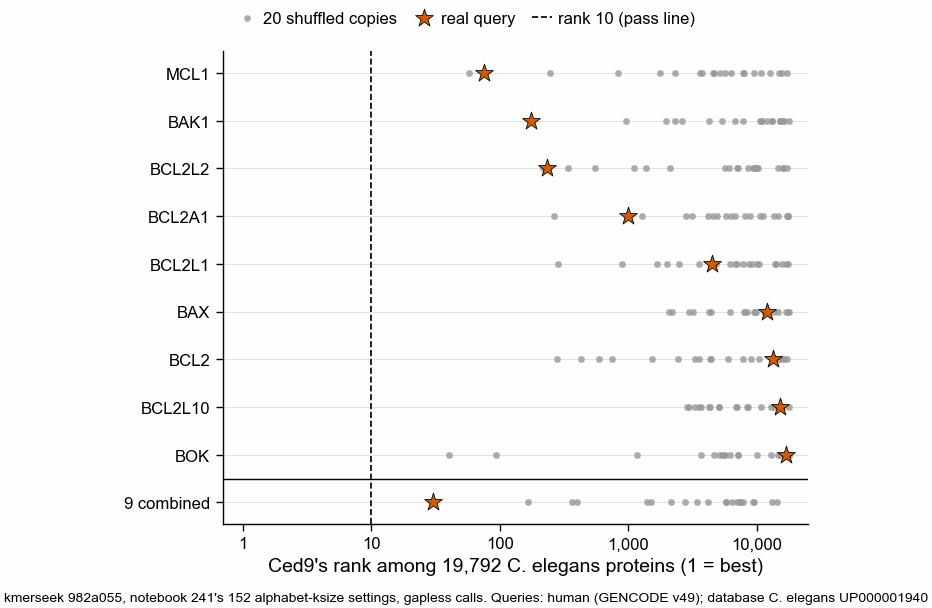

In [2]:
w = single["worm"].with_columns(member=pl.col("query").str.split("_shuf").list.first(),
                                shuffled=pl.col("query").str.contains("_shuf"))
real = w.filter(~pl.col("shuffled")).sort("partner_rank")
print("Ced9's rank for each query alone (19_792 worm proteins; ties printed):")
print(real.select("query", "partner_log10_p", "partner_rank", "partner_n_tied"))
sh = w.filter(pl.col("shuffled")).group_by("member").agg(
    shuffles_better=(pl.col("partner_rank") < pl.first("partner_rank")).sum(),
    shuffle_best_rank=pl.col("partner_rank").min(), shuffle_median_rank=pl.col("partner_rank").median())
tab = real.join(sh, left_on="query", right_on="member").select(
    "query", "partner_rank", "shuffle_best_rank", "shuffle_median_rank")
tab = tab.with_columns(shuffles_ranked_better=pl.struct("query", "partner_rank").map_elements(
    lambda r: int((w.filter((pl.col("member") == r["query"]) & pl.col("shuffled"))["partner_rank"]
                   < r["partner_rank"]).sum()), return_dtype=pl.Int64))
print(tab)
pr = pooled.filter(pl.col("pool") == "real").row(0, named=True)
ps = pooled.filter(pl.col("pool") != "real")
print(f"\nNine members combined: Ced9 rank {pr['partner_rank']} (ties {pr['partner_n_tied']}), "
      f"10^{pr['partner_log10_p']:.2f} at Ced9 residue {pr['partner_best_residue0'] + 1}, "
      f"{pr['partner_n_queries_there']} of 9 members with a call there. Shuffled pools: best rank "
      f"{ps['partner_rank'].min()}, median {ps['partner_rank'].median():.0f}; "
      f"{int((ps['partner_log10_p'] < pr['partner_log10_p']).sum())} of 20 score better than the real family.")

rows = list(real["query"]) + ["9 combined"]
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 78)
for i, q in enumerate(rows):
    if q == "9 combined":
        r_real, r_sh = pr["partner_rank"], ps["partner_rank"].to_numpy()
    else:
        r_real = real.filter(pl.col("query") == q)["partner_rank"][0]
        r_sh = w.filter((pl.col("member") == q) & pl.col("shuffled"))["partner_rank"].to_numpy()
    ax.scatter(r_sh, np.full(len(r_sh), i), s=6, color=pf.GREY, lw=0, alpha=0.8,
               label="20 shuffled copies" if i == 0 else None)
    ax.scatter([r_real], [i], marker="*", s=45, color=C["vermillion"], edgecolor="black", lw=0.3,
               zorder=3, label="real query" if i == 0 else None)
    ax.axhline(i, color="#DDDDDD", lw=0.3, zorder=0)
ax.axvline(10, color="black", ls="--", lw=0.6, label="rank 10 (pass line)")
ax.set_xscale("log")
ticks = [1, 10, 100, 1000, 10_000]
ax.set_xticks(ticks, ["1", "10", "100", "1,000", "10,000"]); ax.minorticks_off()
ax.set_xlim(0.7, 25_000)
ax.set_yticks(range(len(rows)), rows); ax.invert_yaxis()
ax.axhline(len(rows) - 1.5, color="black", lw=0.5)
ax.set_xlabel("Ced9's rank among 19,792 C. elegans proteins (1 = best)")
pf.shared_legend(fig, ncol=3)
fig.supxlabel(TOOL + "; database C. elegans UP000001940", fontsize=5)
pf.save(fig, FIG / "289_ced9_rank_per_bcl2_family_query_celegans")

## 2. Where on Ced9 the calls land, and the real residues

Top: Ced9 as a line, with its BH4, BH1 and BH2 motifs (UniProt) as boxes. Middle: one row per
human query; the colour is the strongest per-protein evidence, $-\log_{10} p$, from any call
covering that Ced9 residue; white is no call. Bottom: the nine combined (Fisher's method) at
each Ced9 residue; higher is stronger.

A call is **in register** on a motif when its diagonal (query start minus Ced9 start) is
within 1 residue of the diagonal that puts the member's motif on Ced9's same motif (UniProt
coordinates), the rule of notebook 284.

combined score recomputed from the per-residue table: 10^-6.94, at Ced9 residues 168-176 (9 residues tied)

Each query's strongest call on Ced9 (E-value for the 19,792-protein worm database):

MCL1  dayhoff6 k=14  E = 5.1  10 of 18 identical  in register on: BH1
  MCL1     261 WGRIVTLISFGAFVAKHL 278
                ||   ||||| |||   
  Ced9     168 YGRLIGLISFGGFVAAKM 185

BAK1  dayhoff6 k=11  E = 7.6  6 of 25 identical  in register on: BH1
  BAK1     120 ESGINWGRVVALLGFGYRLALHVYQ 144
                     ||   |  ||   |     
  Ced9     163 QCPMSYGRLIGLISFGGFVAAKMME 187

BCL2L2  wwmj5 k=7  E = 10.4  17 of 56 identical  in register on: BH4
  BCL2L2    13 LVADFVGYKLRQKGYVCGAGPGEGPAADPLHQAMRAAGDEFETRFRRTFSDLAAQL 68
                | |      || |      ||      | |  ||  |  ||      |     ||
  Ced9      83 FVVDYFTHRIRQNGMEWFGAPGLPCGVQPEHEMMRVMGTIFEKKHAENFETFCEQL 138

BCL2A1  dayhoff6 k=7  E = 57.5  6 of 31 identical  in register on: BH1
  BCL2A1    74 VMEKEFEDGIINWGRIVTIFAFEGILIKKLL 104
          

shape: (9, 4)
┌─────────┬─────────────────────────┬─────────────────┬────────────────┐
│ query   ┆ strongest_minus_log10_p ┆ at_ced9_residue ┆ at_residue_169 │
│ ---     ┆ ---                     ┆ ---             ┆ ---            │
│ str     ┆ f64                     ┆ i64             ┆ f64            │
╞═════════╪═════════════════════════╪═════════════════╪════════════════╡
│ MCL1    ┆ 3.75                    ┆ 168             ┆ 3.75           │
│ BAK1    ┆ 3.58                    ┆ 163             ┆ 3.58           │
│ BCL2L2  ┆ 3.45                    ┆ 83              ┆ 1.46           │
│ BCL2A1  ┆ 2.7                     ┆ 156             ┆ 2.7            │
│ BCL2L1  ┆ 1.88                    ┆ 156             ┆ 1.88           │
│ BAX     ┆ 0.94                    ┆ 71              ┆ 0.32           │
│ BCL2    ┆ 0.84                    ┆ 78              ┆ 0.44           │
│ BCL2L10 ┆ 0.53                    ┆ 160             ┆ 0.53           │
│ BOK     ┆ 0.06                    ┆

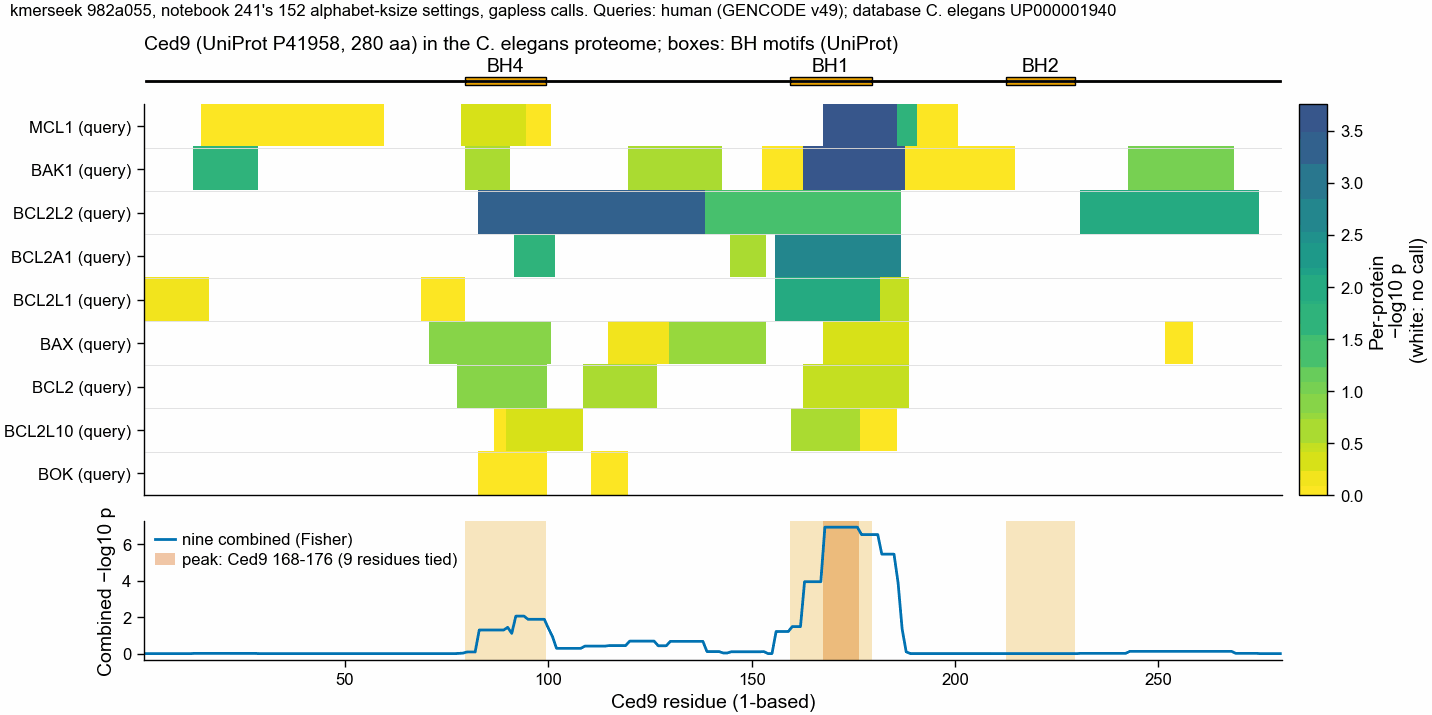

In [3]:
ev = pl.read_csv(S / "worm" / "289_partner_residue_evidence.csv")
L = 280
order = list(real.sort("partner_rank")["query"])
M = np.zeros((len(order), L))
for i, q in enumerate(order):
    e = ev.filter(pl.col("query_name") == q)
    M[i, e["r"].to_numpy()] = e["neg_ln_p"].to_numpy()
M10 = M / np.log(10)
comb = -chi2.logsf(2 * M.sum(axis=0), 2 * len(FAMILY)) / np.log(10)
best = int(np.argmax(comb))
# The job reports one best residue; several residues can share the top value (they differ
# only by floating-point rounding), so check the value and that the job's residue is among them.
tied = np.flatnonzero(np.isclose(comb, comb.max(), rtol=0, atol=1e-9)) + 1
assert abs(comb.max() + pr["partner_log10_p"]) < 1e-6 and pr["partner_best_residue0"] + 1 in tied, (comb.max(), tied)
best = pr["partner_best_residue0"]
print(f"combined score recomputed from the per-residue table: 10^-{comb.max():.2f}, "
      f"at Ced9 residues {tied.min()}-{tied.max()} ({len(tied)} residues tied)")


def register(row) -> str:
    out = []
    for mot in ("BH4", "BH1", "BH2", "BH3"):
        m = motifs.filter((pl.col("gene") == row["query_name"]) & (pl.col("motif") == mot))
        c9 = motifs.filter((pl.col("gene") == "Ced9") & (pl.col("motif") == mot))
        if m.height and c9.height:
            want = m["start1"][0] - c9["start1"][0]
            have = int(row["region_start"]) - int(row["target_start"])
            covers = row["target_start"] < c9["end1"][0] and row["target_end"] > c9["start1"][0] - 1
            if abs(have - want) <= 1 and covers:
                out.append(mot)
    return ",".join(out) or "no"


cw = calls["worm"].sort("neg_ln_p", "alphabet", "ksize", descending=[True, False, False]).group_by(
    "query_name", maintain_order=True).first().sort("neg_ln_p", descending=True)
cw = cw.with_columns(in_register=pl.struct(cw.columns).map_elements(register, return_dtype=pl.String))
print("\nEach query's strongest call on Ced9 (E-value for the 19,792-protein worm database):")
for r in cw.iter_rows(named=True):
    a, b = r["query_residues"], r["target_residues"]
    m = "".join("|" if x == y else " " for x, y in zip(a, b))
    print(f"\n{r['query_name']}  {r['alphabet']} k={r['ksize']}  E = {r['region_evalue']:.1f}  "
          f"{m.count('|')} of {len(a)} identical  in register on: {r['in_register']}")
    print(f"  {r['query_name']:<8}{int(r['region_start']) + 1:>4} {a} {int(r['region_end'])}")
    print(f"  {'':<8}{'':>4} {m}")
    print(f"  {'Ced9':<8}{int(r['target_start']) + 1:>4} {b} {int(r['target_end'])}")

ced = motifs.filter(pl.col("gene") == "Ced9")
fig = plt.figure(figsize=(pf.TWO_COLUMN_MM * pf.MM, 92 * pf.MM), layout="constrained")
gs = fig.add_gridspec(3, 2, height_ratios=[0.5, len(order), 3.2], width_ratios=[40, 1])
a0, a1, a2, cax = (fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[2, 0]),
                   fig.add_subplot(gs[1, 1]))
a0.plot([1, L], [0, 0], color="black", lw=1)
for r in ced.iter_rows(named=True):
    a0.add_patch(mpl.patches.Rectangle((r["start1"] - 0.5, -0.4), r["end1"] - r["start1"] + 1, 0.8,
                                       facecolor=C["orange"], edgecolor="black", lw=0.5))
    a0.text((r["start1"] + r["end1"]) / 2, 0.55, r["motif"], ha="center", va="bottom")
a0.set_ylim(-0.6, 1.4); a0.set_yticks([]); a0.set_xticks([]); a0.set_xlim(0.5, L + 0.5)
a0.spines[["left", "bottom"]].set_visible(False)
a0.set_title("Ced9 (UniProt P41958, 280 aa) in the C. elegans proteome; boxes: BH motifs (UniProt)", loc="left")
cmap = mpl.colors.ListedColormap(plt.get_cmap("viridis")(np.linspace(0.25, 1, 256))[::-1])
cmap.set_bad("white")
im = a1.imshow(np.ma.masked_where(M10 <= 0, M10), aspect="auto", cmap=cmap, interpolation="nearest",
               extent=(0.5, L + 0.5, len(order) - 0.5, -0.5), vmin=0, vmax=float(M10.max()))
a1.set_yticks(range(len(order)), [f"{q} (query)" for q in order])
for i in range(len(order)):
    a1.axhline(i + 0.5, color="#DDDDDD", lw=0.3)
a1.set_xlim(0.5, L + 0.5); a1.set_xticks([])
fig.colorbar(im, cax=cax, label="Per-protein\n−log10 p\n(white: no call)")
a2.plot(np.arange(1, L + 1), comb, color=C["blue"], lw=1, label="nine combined (Fisher)")
a2.axvspan(tied.min() - 0.5, tied.max() + 0.5, color=C["vermillion"], alpha=0.35, lw=0,
            label=f"peak: Ced9 {tied.min()}-{tied.max()} ({len(tied)} residues tied)")
for r in ced.iter_rows(named=True):
    a2.axvspan(r["start1"] - 0.5, r["end1"] + 0.5, color=C["orange"], alpha=0.25, lw=0)
a2.set_xlim(0.5, L + 0.5); a2.set_xlabel("Ced9 residue (1-based)"); a2.set_ylabel("Combined −log10 p")
a2.legend(loc="upper left", frameon=False)
fig.suptitle(TOOL + "; database C. elegans UP000001940", fontsize=6, x=0.01, ha="left")
pf.save(fig, FIG / "289_bcl2_family_evidence_along_ced9_celegans")
print(pl.DataFrame({"query": order, "strongest_minus_log10_p": M10.max(axis=1).round(2),
                    "at_ced9_residue": M10.argmax(axis=1) + 1,
                    f"at_residue_{best + 1}": M10[:, best].round(2)}))

## 3. What ranks above Ced9 for the nine combined

The 25 worm proteins with the best combined score, with their UniProt gene names (`GN=` in the
proteome FASTA headers). Ced9 is 30th.

shape: (25, 5)
┌──────┬─────────────────┬────────────────────────┬────────────────────────┬─────────────────┐
│ rank ┆ gene            ┆ target_name            ┆ combined_minus_log10_p ┆ n_queries_there │
│ ---  ┆ ---             ┆ ---                    ┆ ---                    ┆ ---             │
│ u32  ┆ str             ┆ str                    ┆ f64                    ┆ i64             │
╞══════╪═════════════════╪════════════════════════╪════════════════════════╪═════════════════╡
│ 1    ┆ acd-5           ┆ tr|O01664|O01664_CAEEL ┆ 12.04                  ┆ 8               │
│ 2    ┆ CELE_T13C5.7    ┆ tr|Q8T3C9|Q8T3C9_CAEEL ┆ 10.37                  ┆ 9               │
│ 3    ┆ CELE_VW02B12L.2 ┆ tr|Q9XXA1|Q9XXA1_CAEEL ┆ 10.09                  ┆ 9               │
│ 4    ┆ mrpl-16         ┆ tr|Q22140|Q22140_CAEEL ┆ 9.07                   ┆ 8               │
│ 5    ┆ CELE_F54F7.9    ┆ tr|A3FPK6|A3FPK6_CAEEL ┆ 8.8                    ┆ 7               │
│ 6    ┆ CELE_F59A1.6    ┆ tr|Q9XUV

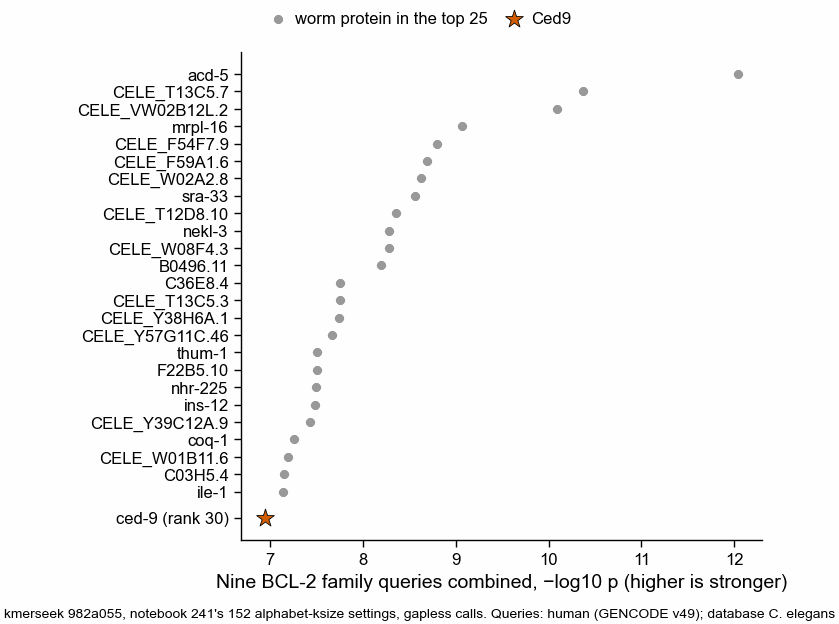

In [4]:
gn = {}
with gzip.open("/Users/olga/data/uniprot/reference_proteomes/UP000001940_6239.fasta.gz", "rt") as fh:
    for line in fh:
        if line.startswith(">"):
            name = line[1:].split()[0]
            gene = [t[3:] for t in line.split() if t.startswith("GN=")]
            gn[name] = gene[0] if gene else ""
top = pl.read_csv(S / "worm" / "289_pooled_top25.csv").with_row_index("rank", offset=1).with_columns(
    gene=pl.col("target_name").replace_strict(gn, default=""),
    combined_minus_log10_p=(-pl.col("log10_p")).round(2))
print(top.select("rank", "gene", "target_name", "combined_minus_log10_p", "n_queries_there"))
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 80)
y = np.arange(top.height + 1)
vals = list(top["combined_minus_log10_p"]) + [-pr["partner_log10_p"]]
labels = [f"{g or t.split('|')[1]}" for g, t in zip(top["gene"], top["target_name"])] + ["ced-9 (rank 30)"]
ax.scatter(vals[:-1], y[:-1], s=8, color=pf.GREY, label="worm protein in the top 25")
ax.scatter([vals[-1]], [y[-1] + 0.5], marker="*", s=45, color=C["vermillion"], edgecolor="black", lw=0.3,
           label="Ced9")
for i in range(top.height):
    ax.axhline(i, color="#EEEEEE", lw=0.3, zorder=0)
ax.set_yticks(list(y[:-1]) + [y[-1] + 0.5], labels[:-1] + [labels[-1]])
ax.invert_yaxis()
ax.set_xlabel("Nine BCL-2 family queries combined, −log10 p (higher is stronger)")
pf.shared_legend(fig, ncol=2)
fig.supxlabel(TOOL + "; database C. elegans", fontsize=5)
pf.save(fig, FIG / "289_bcl2_family_combined_top25_celegans")

## 4. CD47 → P66 in *B. burgdorferi* B31

CD47 has no paralog in human (Ensembl 115, notebook 285), so it is one query. Its strongest
calls on P66 are printed with their residues and the UniProt features they cover. In the figure,
each protein is a line with its UniProt features as boxes; each call is a bar under the two
proteins, joined by a dotted line.

P66's rank for CD47: 381 of 1_291 B31 proteins (ties 1), 10^-1.59. Shuffled CD47: best rank 52, median 451; 8 of 20 score P66 better.

CD47 86-105 -> P66 123-142  sdm12 k=6  E = 16.3  5 of 20 identical
  CD47    86 IEVSQLLKGDASLKMDKSDA 105   CD47 features: Domain Ig-like V-type 19-127
             |  |     |       | |
  P66    123 IKISTMTDFDFNKESLFSFA 142   P66 features: none

CD47 68-81 -> P66 282-295  wwmj5 k=7  E = 34.8  3 of 14 identical
  CD47    68 FDGALNKSTVPTDF 81   CD47 features: Domain Ig-like V-type 19-127
                 |  |     |
  P66    282 LSPTLSNSAILASF 295   P66 features: none

CD47 282-319 -> P66 137-174  hp_kyte_doolittle2 k=17  E = 62.3  8 of 38 identical
  CD47   282 QLLGLVYMKFVASNQKTIQPPRKAVEEPLNAFKESKGM 319   CD47 features: Transmembrane Helical 269-289
              |     |    |          ||     |   ||  
  P66    137 SLFSFAPMTGFKSTYYGFPSNDRAVRGTILARGTSKNI 174   P66 features: none

CD47 307-313 -> P66 81-87  wwmj5 k=7  E = 101.6  2 of 7 identical
  CD47   307 E

shape: (5, 7)
┌────────────────────┬───────┬──────────────┬────────────┬──────────────┬────────────┬───────────────┐
│ alphabet           ┆ ksize ┆ region_start ┆ region_end ┆ target_start ┆ target_end ┆ region_evalue │
│ ---                ┆ ---   ┆ ---          ┆ ---        ┆ ---          ┆ ---        ┆ ---           │
│ str                ┆ i64   ┆ f64          ┆ f64        ┆ f64          ┆ f64        ┆ f64           │
╞════════════════════╪═══════╪══════════════╪════════════╪══════════════╪════════════╪═══════════════╡
│ sdm12              ┆ 6     ┆ 85.0         ┆ 105.0      ┆ 122.0        ┆ 142.0      ┆ 16.251027     │
│ wwmj5              ┆ 7     ┆ 67.0         ┆ 81.0       ┆ 281.0        ┆ 295.0      ┆ 34.823546     │
│ hp_kyte_doolittle2 ┆ 17    ┆ 281.0        ┆ 319.0      ┆ 136.0        ┆ 174.0      ┆ 62.298006     │
│ wwmj5              ┆ 7     ┆ 306.0        ┆ 313.0      ┆ 80.0         ┆ 87.0       ┆ 101.593853    │
│ hp_lehninger2      ┆ 17    ┆ 9.0          ┆ 34.0       ┆ 

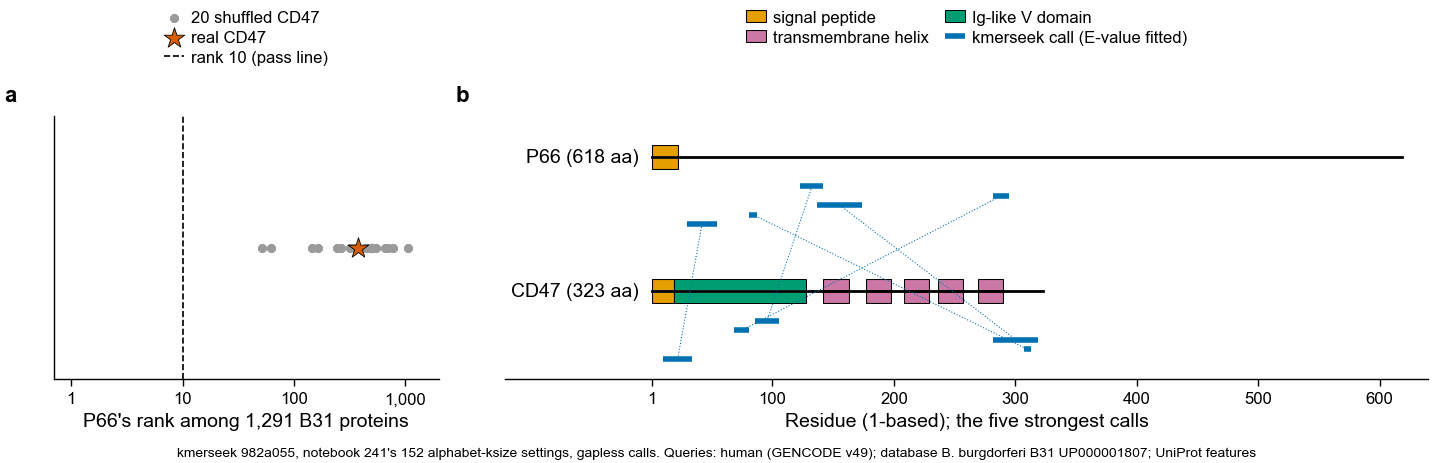

In [5]:
b = single["borrelia"].with_columns(shuffled=pl.col("query").str.contains("_shuf"))
cd = b.filter(~pl.col("shuffled")).row(0, named=True)
bs = b.filter(pl.col("shuffled"))
print(f"P66's rank for CD47: {cd['partner_rank']} of {cd['n_targets']:_} B31 proteins "
      f"(ties {cd['partner_n_tied']}), 10^{cd['partner_log10_p']:.2f}. Shuffled CD47: best rank "
      f"{bs['partner_rank'].min()}, median {bs['partner_rank'].median():.0f}; "
      f"{int((bs['partner_log10_p'] < cd['partner_log10_p']).sum())} of 20 score P66 better.")
cb = calls["borrelia"].filter(pl.col("query_name") == "CD47").sort("neg_ln_p", descending=True)


def feat(prot: str, a: int, z: int) -> str:
    f = feats.filter((pl.col("protein") == prot) & (pl.col("start1") <= z) & (pl.col("end1") >= a))
    return "; ".join(f"{x} {s}-{e}" for x, s, e in f.select("feature", "start1", "end1").iter_rows()) or "none"


top_cb = cb.unique(["region_start", "target_start"], keep="first", maintain_order=True).head(5)
for r in top_cb.iter_rows(named=True):
    a, z = r["query_residues"], r["target_residues"]
    m = "".join("|" if x == y else " " for x, y in zip(a, z))
    qa, qz, ta, tz = int(r["region_start"]) + 1, int(r["region_end"]), int(r["target_start"]) + 1, int(r["target_end"])
    print(f"\nCD47 {qa}-{qz} -> P66 {ta}-{tz}  {r['alphabet']} k={r['ksize']}  E = {r['region_evalue']:.1f}  "
          f"{m.count('|')} of {len(a)} identical")
    print(f"  {'CD47':<6}{qa:>4} {a} {qz}   CD47 features: {feat('CD47', qa, qz)}")
    print(f"  {'':<6}{'':>4} {m}")
    print(f"  {'P66':<6}{ta:>4} {z} {tz}   P66 features: {feat('P66', ta, tz)}")

fig = plt.figure(figsize=(pf.TWO_COLUMN_MM * pf.MM, 60 * pf.MM), layout="constrained")
g = fig.add_gridspec(1, 2, width_ratios=[1, 2.4])
a, bx = fig.add_subplot(g[0]), fig.add_subplot(g[1])
a.scatter(bs["partner_rank"], np.zeros(bs.height), s=8, color=pf.GREY, label="20 shuffled CD47")
a.scatter([cd["partner_rank"]], [0], marker="*", s=60, color=C["vermillion"], edgecolor="black", lw=0.3,
          zorder=3, label="real CD47")
a.axvline(10, color="black", ls="--", lw=0.6, label="rank 10 (pass line)")
a.set_xscale("log"); a.set_xticks([1, 10, 100, 1000], ["1", "10", "100", "1,000"]); a.minorticks_off()
a.set_xlim(0.7, 2000); a.set_yticks([])
a.set_xlabel("P66's rank among 1,291 B31 proteins")
a.legend(loc="upper center", bbox_to_anchor=(0.5, 1.45), frameon=False)
prot = {"P66": (618, 1.0), "CD47": (323, 0.0)}
colours = {"Signal": C["orange"], "Domain Ig-like V-type": C["bluish_green"], "Transmembrane Helical": C["reddish_purple"]}
names = {"Signal": "signal peptide", "Domain Ig-like V-type": "Ig-like V domain", "Transmembrane Helical": "transmembrane helix"}
seen = set()
for p_, (length, yy) in prot.items():
    bx.plot([1, length], [yy, yy], color="black", lw=1)
    bx.text(-10, yy, f"{p_} ({length} aa)", ha="right", va="center")
    for f, s_, e_ in feats.filter(pl.col("protein") == p_).select("feature", "start1", "end1").iter_rows():
        bx.add_patch(mpl.patches.Rectangle((s_, yy - 0.09), e_ - s_ + 1, 0.18, facecolor=colours[f],
                                           edgecolor="black", lw=0.4, label=names[f] if f not in seen else None))
        seen.add(f)
for j, r in enumerate(top_cb.iter_rows(named=True)):
    qa, qz, ta, tz = int(r["region_start"]) + 1, int(r["region_end"]), int(r["target_start"]) + 1, int(r["target_end"])
    yp, yc = 0.78 - 0.07 * j, -0.22 - 0.07 * j
    bx.plot([ta, tz], [yp, yp], color=C["blue"], lw=2, solid_capstyle="butt",
            label="kmerseek call (E-value fitted)" if j == 0 else None)
    bx.plot([qa, qz], [yc, yc], color=C["blue"], lw=2, solid_capstyle="butt")
    bx.plot([(ta + tz) / 2, (qa + qz) / 2], [yp, yc], color=C["blue"], lw=0.4, ls=":")
bx.set_xlim(-120, 640); bx.set_ylim(-0.65, 1.3); bx.set_yticks([]); bx.spines["left"].set_visible(False)
bx.set_xticks([1, 100, 200, 300, 400, 500, 600]); bx.set_xlabel("Residue (1-based); the five strongest calls")
bx.legend(loc="upper center", bbox_to_anchor=(0.5, 1.45), ncol=2, frameon=False)
pf.panel_label(a, "a"); pf.panel_label(bx, "b")
fig.supxlabel(TOOL + "; database B. burgdorferi B31 UP000001807; UniProt features", fontsize=5)
pf.save(fig, FIG / "289_cd47_to_p66_borrelia_b31")
print(top_cb.select("alphabet", "ksize", "region_start", "region_end", "target_start", "target_end", "region_evalue"))

## 5. Verdict

shape: (2, 5)
┌─────────────────────────────┬──────┬───────────┬─────────────────┬───────┐
│ case                        ┆ rank ┆ n_targets ┆ shuffles_beaten ┆ pass  │
│ ---                         ┆ ---  ┆ ---       ┆ ---             ┆ ---   │
│ str                         ┆ i64  ┆ i64       ┆ i64             ┆ bool  │
╞═════════════════════════════╪══════╪═══════════╪═════════════════╪═══════╡
│ pooled BCL-2 family -> Ced9 ┆ 30   ┆ 19792     ┆ 20              ┆ false │
│ CD47 -> P66                 ┆ 381  ┆ 1291      ┆ 12              ┆ false │
└─────────────────────────────┴──────┴───────────┴─────────────────┴───────┘


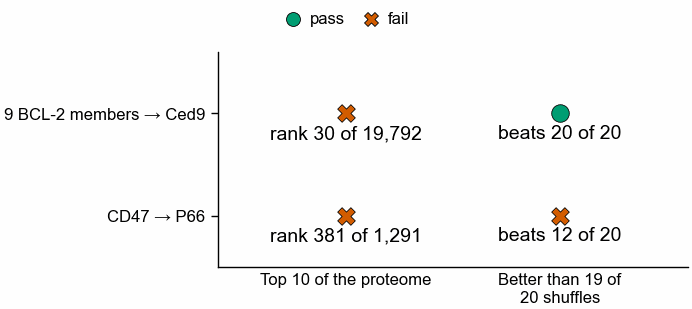

In [6]:
verd = [json.loads((S / s / "289_verdict.json").read_text()) for s in ("worm", "borrelia")]
v = pl.DataFrame(verd)
print(v)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 40)
style = {True: ("o", C["bluish_green"]), False: ("X", C["vermillion"])}
for yi, r in enumerate(verd):
    for xi, (ok, note) in enumerate([(r["rank"] <= 10, f"rank {r['rank']} of {r['n_targets']:,}"),
                                     (r["shuffles_beaten"] >= 19, f"beats {r['shuffles_beaten']} of 20")]):
        m, col = style[ok]
        ax.scatter(xi, yi, marker=m, s=40, color=col, edgecolor="black", lw=0.3)
        ax.annotate(note, (xi, yi), xytext=(0, -9), textcoords="offset points", ha="center")
for ok, (m, col) in style.items():
    ax.scatter([], [], marker=m, s=25, color=col, edgecolor="black", lw=0.3, label="pass" if ok else "fail")
ax.set_xticks([0, 1], ["Top 10 of the proteome", "Better than 19 of\n20 shuffles"])
ax.set_yticks([0, 1], ["9 BCL-2 members → Ced9", "CD47 → P66"])
ax.set_xlim(-0.6, 1.6); ax.set_ylim(1.5, -0.6); ax.tick_params(axis="x", length=0)
pf.shared_legend(fig, ncol=2)
pf.save(fig, FIG / "289_decision_reverse_search")

# Summary and Conclusions

## Background

Notebooks 241 and 285 searched Ced9 and P66 against human proteins and never brought BCL2 or
CD47 near the top. This notebook searches the other way at the same 152 settings: the nine
human BCL-2 family members against the *C. elegans* proteome, and CD47 against *B. burgdorferi*
B31, with 20 shuffled copies of every query as the null.

## Summary and Conclusions

* Combining the nine human BCL-2 family members ranks Ced9 30th of 19_792 worm proteins,
  better than all 20 shuffled families (best 165th), but outside the top 10, so the test fails.
* MCL1 alone ranks Ced9 75th and BAK1 176th, both with BH1-to-BH1 calls at E < 10 in the worm
  database; BCL2 alone ranks Ced9 13_287th.
* MCL1, BAK1, BCL2L2 and BCL2A1 each rank Ced9 above at least 19 of their own 20 shuffled
  copies; BCL2, BAX, BOK and BCL2L10 do not (14 to 17 of 20 shuffles do better).
* CD47 ranks P66 381st of 1_291 B31 proteins, and 8 of its 20 shuffled copies give P66 a better score
  (9 of 20 give it a better rank),
  so the reverse search gives no evidence for CD47 → P66; its best call (E = 16.3) joins CD47's
  Ig-like V domain (86-105) to P66 123-142, 5 of 20 residues identical.

## Analysis Details

The combined score peaks on Ced9 residues 168-176 (9 residues tie), inside BH1 (160-179), where
8 of the 9 members have a call. Each member's strongest call on Ced9 is in register on the
member's own motif for 6 of the 9: BH1 for MCL1, BAK1 and BCL2A1, and BH4 for BCL2L2, BCL2 and
BOK; BCL2L1, BAX and BCL2L10 land elsewhere. The proteins ranked above Ced9 are worm
proteins that several queries reach at once, as in notebook 285, where large families
outranked the BCL-2 family. The score is a ranking score, not a p-value. The chained (gapped)
copy of this run (job 48677816) was still running when this notebook was written.

## Supplementary Information

- Scripts: `289_reverse_search.py` (rule committed in 2f629f6), `289_reverse_search.sbatch`,
  `289_build_notebook.py`. Job 48677815: 1 h 44 min, 16 CPUs; Slurm reported 64.0 GB used of the
  64 GB asked (100%), with no task killed and all 152 searches exiting 0. That figure likely
  includes file cache, so the real need is not known; a rerun should ask 128 GB.
- Notebook 241's reciprocal job (47664560, PR 46) searched BCL2 alone and CD47 alone the same
  way and ranks within each setting's hit list; this notebook ranks among all proteins.

## References

- UniProt reference proteomes UP000001940 and UP000001807, release 2026_03.
- Altschul, S. F., and B. W. Erickson. "Significance of Nucleotide Sequence Alignments: A
  Method for Random Sequence Permutation That Preserves Dinucleotide and Codon Usage."
  *Molecular Biology and Evolution* 2, no. 6 (1985): 526–38.